In [1]:
import os
import time
import platform
from shutil import rmtree
from dotenv import load_dotenv

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.image as image
import seaborn as sns

import sklearn
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report
from PIL import Image

import torch
import torch.nn as nn
import torch.optim as optim
import torch.nn.functional as F
from torch.utils.data import DataLoader, Dataset, TensorDataset, random_split

import torchvision
import torchvision.transforms as transforms
import torchvision.models as models
from torchvision.datasets import ImageFolder
from torchvision.utils import make_grid

# 1. 운영체제별 한글 폰트 설정
if platform.system() == 'Windows':
    plt.rc('font', family='Malgun Gothic')
elif platform.system() == 'Darwin':  # Mac OS
    plt.rc('font', family='AppleGothic')
else:  # Linux (Colab 등)
    plt.rc('font', family='NanumBarunGothic')

# 2. 마이너스 기호(-) 깨짐 방지
plt.rcParams['axes.unicode_minus'] = False

# 오류 발생시
sklearn.set_config(display="text")

In [2]:
train_transform = transforms.Compose([
    transforms.Resize((64, 64)),
    transforms.Grayscale(1),
    transforms.ToTensor(),
    transforms.Normalize(0.5, 0.5),
])

test_transform = transforms.Compose([
    transforms.Resize((64, 64)),
    transforms.Grayscale(1),
    transforms.ToTensor(),
    transforms.Normalize(0.5, 0.5),
])

In [3]:
base_path = r"C:\kdt_0900_hhj\ml\resource\dataset"
train_path = os.path.join(base_path, "shape", "train")
test_path = os.path.join(base_path, "shape", "test")

In [6]:
# 데이터 (이미지) 불러오기
train_dataset = ImageFolder(train_path, transform=train_transform)
test_dataset = ImageFolder(test_path, transform=test_transform)

print(len(train_dataset), len(test_dataset))

240 60


In [8]:
class_dict = dict(enumerate(train_dataset.classes))
class_dict

{0: 'cir', 1: 'tri', 2: 'x'}

In [ ]:
# DataLoader 만들기
# 이미지 확인하기
# CNN 모델 만들기
# 모델 학습하기
# 테스트 데이터로 정확도 확인하기

### DataLoader

In [9]:
train_dataloader = DataLoader(train_dataset, batch_size=64, shuffle=True)
test_dataloader = DataLoader(test_dataset, batch_size=64, shuffle=False)

In [49]:
print(len(train_dataset), len(test_dataset))
print(len(train_dataloader), len(test_dataloader))

240 60
4 1


In [14]:
img, label = train_dataset[0]

print(img.shape)
print(label)

torch.Size([1, 64, 64])
0


In [67]:
print(imgs.size())

torch.Size([60, 1, 64, 64])


### 이미지 확인하기

In [18]:
imgs, labels = next(iter(train_dataloader))

In [70]:
print(len(imgs), len(labels))

60 60


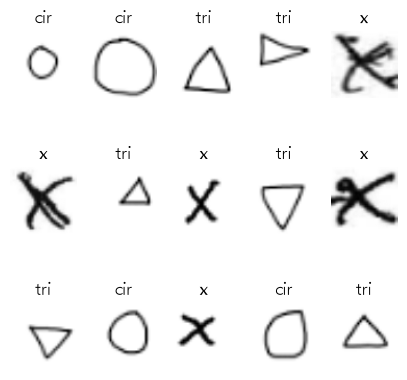

In [46]:
fig, axes = plt.subplots(3, 5, figsize=(5, 5))

for i, ax in enumerate(axes.flatten()):
    ax.imshow(imgs[i].squeeze(), cmap="gray")
    ax.set_title(train_dataset.classes[labels[i].item()])
    ax.axis("off")

plt.show()

### CNN 모델 만들기

In [47]:
if torch.cuda.is_available():
    device = torch.device("cuda")
elif torch.mps.is_available():
    device = torch.device("mps")
elif torch.xpu.is_available():
    device = torch.device("xpu")
else:
    device = torch.device("cpu")

print(f"현재 선택된 장치: {device}")

현재 선택된 장치: cuda


In [51]:
class ConvNeuralNetwork(nn.Module):
    def __init__(self):
        super(ConvNeuralNetwork, self).__init__()
        
        self.flatten = nn.Flatten()
        
        self.classifier = nn.Sequential(
            nn.Conv2d(1, 28, kernel_size=3, padding="same"), #64, 64
            nn.ReLU(), # 활성화 함수(선형 -> 비선형)
            
            nn.Conv2d(28, 28, kernel_size=3, padding="same"),
            nn.ReLU(),
            
            nn.MaxPool2d(kernel_size=2), # 32, 32
            nn.Dropout(0.25),
            
            nn.Conv2d(28, 56, kernel_size=3, padding="same"),
            nn.ReLU(),
            
            nn.Conv2d(56, 56, kernel_size=3, padding="same"),
            nn.ReLU(),
            
            nn.MaxPool2d(kernel_size=2), # 16, 16
            nn.Dropout(0.25)
        )
        self.linear = nn.Linear(56 * 16 * 16, 3)
    
    def forward(self, x):
        x = self.classifier(x)
        x = self.flatten(x)
        x = self.linear(x)
        return x

In [52]:
model = ConvNeuralNetwork().to(device)

In [53]:
model

ConvNeuralNetwork(
  (flatten): Flatten(start_dim=1, end_dim=-1)
  (classifier): Sequential(
    (0): Conv2d(1, 28, kernel_size=(3, 3), stride=(1, 1), padding=same)
    (1): ReLU()
    (2): Conv2d(28, 28, kernel_size=(3, 3), stride=(1, 1), padding=same)
    (3): ReLU()
    (4): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (5): Dropout(p=0.25, inplace=False)
    (6): Conv2d(28, 56, kernel_size=(3, 3), stride=(1, 1), padding=same)
    (7): ReLU()
    (8): Conv2d(56, 56, kernel_size=(3, 3), stride=(1, 1), padding=same)
    (9): ReLU()
    (10): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (11): Dropout(p=0.25, inplace=False)
  )
  (linear): Linear(in_features=14336, out_features=3, bias=True)
)

In [54]:
criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(model.parameters(), lr=0.001)

In [55]:
def train_one_epoch(model, dataloader, criterion, optimizer, device, log_step=20):
    model.train()
    total = 0
    running_loss = 0.0
    running_corrects = 0

    for i, (imgs, labels) in enumerate(dataloader, 1):
        imgs, labels = imgs.to(device), labels.to(device)

        # 초기화
        optimizer.zero_grad()
        outputs = model(imgs)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()

        batch_size = imgs.size(0)
        running_loss += loss.item() * batch_size
        _, preds = outputs.max(1)
        running_corrects += (preds == labels).sum().item()
        total += batch_size

        if log_step and i % log_step == 0:
            batch_acc = (preds == labels).float().mean().item()
            print(f"[Train] batch {i}/{len(dataloader)} | Loss: {loss:.4f} | Accuracy: {batch_acc:.2f}")

    return running_loss / total, running_corrects / total

In [ ]:
# model: 학습할 CNN 모델
# dataloader: 학습 이미지를 묶음(batch) 단위로 제공
# criterion: 예측이 얼마나 틀렸는지 계산
# optimizer: 모델의 가중치를 업데이트
# device: CPU 또는 GPU
# log_step=20: 20개 배치마다 중간 결과 출력

In [56]:
def evaluate(model, dataloader, criterion, device):
    model.train()

    total = 0
    running_loss = 0.0
    running_corrects = 0

    with torch.no_grad():
        for i, (imgs, labels) in enumerate(dataloader, 1):
            imgs, labels = imgs.to(device), labels.to(device)
    
            # 초기화
            outputs = model(imgs)
            loss = criterion(outputs, labels)
    
            batch_size = imgs.size(0)
            running_loss += loss.item() * batch_size
            _, preds = outputs.max(1)
            running_corrects += (preds == labels).sum().item()
            total += batch_size
    

    return running_loss / total, running_corrects / total

### 학습

In [61]:
epochs = 10

for i in range(epochs):
    # 학습
    train_loss, train_acc = train_one_epoch(
        model=model,
        dataloader=train_dataloader,
        criterion=criterion,
        optimizer=optimizer,
        device=device
    )

    # 평가
    test_loss, test_acc = evaluate(
        model=model,
        dataloader=test_dataloader,
        criterion=criterion,
        device=device
    )

    print(f"Epoch: {i}/{epochs}")
    print(f"[Train] Loss: {train_loss:.4f} | Accuracy: {train_acc:.4f}")
    print(f"[Test] Loss: {test_loss:.4f} | Accuracy: {test_acc:.4f}")

Epoch: 0/10
[Train] Loss: 0.0205 | Accuracy: 0.9958
[Test] Loss: 0.6336 | Accuracy: 0.8333
Epoch: 1/10
[Train] Loss: 0.0089 | Accuracy: 1.0000
[Test] Loss: 0.6282 | Accuracy: 0.8167
Epoch: 2/10
[Train] Loss: 0.0060 | Accuracy: 1.0000
[Test] Loss: 0.6255 | Accuracy: 0.8167
Epoch: 3/10
[Train] Loss: 0.0056 | Accuracy: 1.0000
[Test] Loss: 0.7778 | Accuracy: 0.8167
Epoch: 4/10
[Train] Loss: 0.0042 | Accuracy: 1.0000
[Test] Loss: 0.8371 | Accuracy: 0.8333
Epoch: 5/10
[Train] Loss: 0.0022 | Accuracy: 1.0000
[Test] Loss: 1.0104 | Accuracy: 0.8000
Epoch: 6/10
[Train] Loss: 0.0025 | Accuracy: 1.0000
[Test] Loss: 0.9938 | Accuracy: 0.8167
Epoch: 7/10
[Train] Loss: 0.0055 | Accuracy: 1.0000
[Test] Loss: 1.0525 | Accuracy: 0.8167
Epoch: 8/10
[Train] Loss: 0.0029 | Accuracy: 1.0000
[Test] Loss: 0.7816 | Accuracy: 0.8167
Epoch: 9/10
[Train] Loss: 0.0068 | Accuracy: 0.9958
[Test] Loss: 0.9280 | Accuracy: 0.7833


### 평가

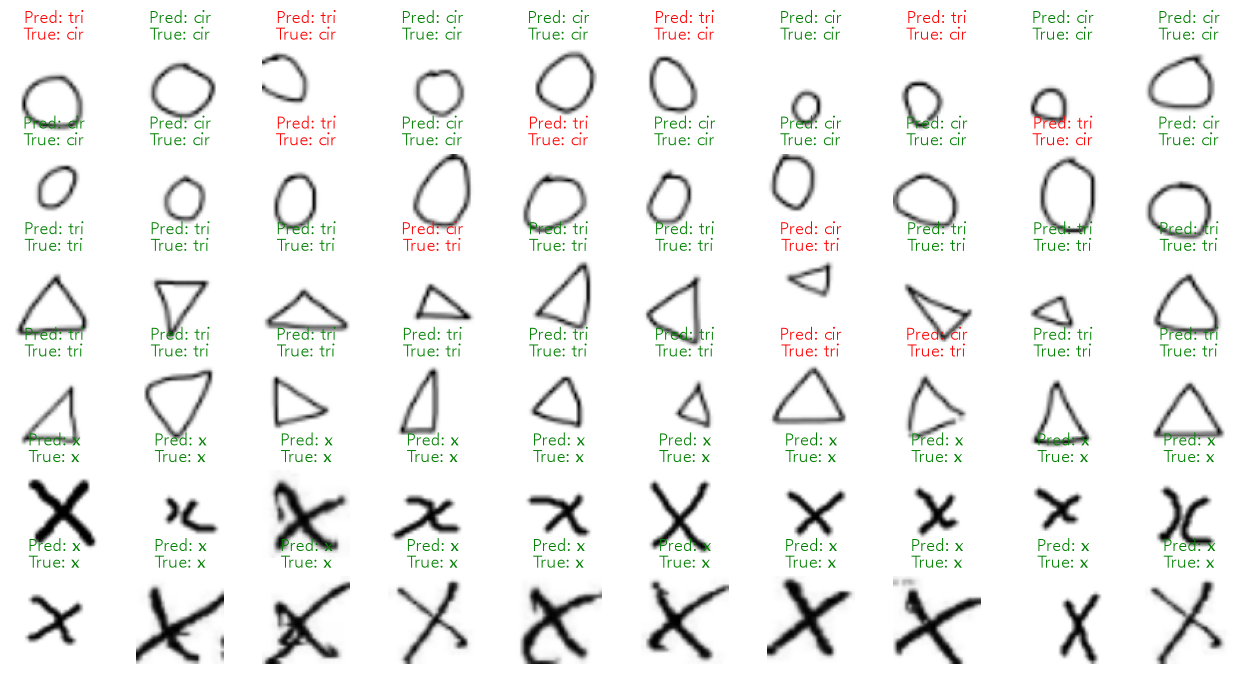

In [71]:
model.eval()

imgs, labels = next(iter(test_dataloader))
imgs_dev = imgs.to(device)

with torch.no_grad():
    outputs = model(imgs_dev)
    _, preds = outputs.max(1)

img_list_cpu = imgs.cpu()
y_pred_list_cpu = preds.cpu()
y_true_list_cpu = labels.cpu()

# 시각화
fig, axes = plt.subplots(6, 10, figsize=(16, 8))

for ax, img, y_pred, y_true in zip(axes.flatten(), img_list_cpu, y_pred_list_cpu, y_true_list_cpu):
    ax.imshow(img.squeeze(), cmap="gray")
    # ax.imshow(img.permute(1, 2, 0), cmap="gray")

    pred_label = class_dict[y_pred.item()]
    true_label = class_dict[y_true.item()]
    color = "green" if pred_label == true_label else "red"
    ax.axis("off")
    ax.set_title(f"Pred: {pred_label}\nTrue: {true_label}", color=color)

plt.show()

In [66]:
print(img_list_cpu.shape)
print(len(y_pred_list_cpu))
print(len(y_true_list_cpu))

torch.Size([60, 1, 64, 64])
60
60
